# LoRA with a classification head (run L4)

Same base model, LoRA settings, training hyperparameters, input and evaluation as L1;
the only intended difference is the output layer: instead of generating the label as text,
a linear classification head over the hypersense labels is trained on top of the model.

This notebook does **not** import unsloth (its fast path targets text generation);
it uses plain `transformers` + `peft` + `bitsandbytes`.

In [ ]:
# Installs transformers, peft, bitsandbytes, accelerate and datasets in compatible versions
# %pip install unsloth

In [12]:
import math, time
import torch, transformers, peft, bitsandbytes
import pandas as pd
import matplotlib.pyplot as plt
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, BitsAndBytesConfig,
                          Trainer, TrainingArguments, DataCollatorWithPadding)
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")
print("transformers", transformers.__version__, "| peft", peft.__version__,
      "| bitsandbytes", bitsandbytes.__version__)

GPU: Tesla T4
transformers 5.16.1 | peft 0.20.0 | bitsandbytes 0.50.2


In [13]:
# Shared code: identical to lab1_shared.py (used by both the ICL and LoRA parts)

import os
import re
import gzip
import random
import urllib.request

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report


# =====================================================================
# 1. Fixed settings -- any change must be made by both team members
# =====================================================================

MODEL_NAME = "unsloth/Qwen2.5-3B-Instruct-bnb-4bit"
SEED = 42
MAX_NEW_TOKENS = 10        # labels are short; 10 new tokens are enough

DEV_SUBSET_N = None        # None = full rand-dev; set an int (e.g. 300) to tune on a fixed subset
DROP_LABELS = []           # hypersenses to exclude (e.g. ["other"]), if we decide to

DATA_URL = ("http://www.linguist.univ-paris-diderot.fr/~mcandito/divers/"
            "super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz")

# Supersense -> hypersense mapping, copied from the lab notebook
SUPER2HYPER = {
    'artifact': 'inanimate',
    'body': 'inanimate',
    'food': 'inanimate',
    'object': 'inanimate',
    'plant': 'inanimate',
    'substance': 'inanimate',
    'act': 'dynamic_situation',
    'event': 'dynamic_situation',
    'phenomenon': 'dynamic_situation',
    'animal': 'animate',
    'person': 'animate',
    'groupxperson': 'animate',
    'cognition': 'information',
    'communication': 'information',
    'quantity': 'quantity',
    'attribute': 'stative_situation',
    'feeling': 'stative_situation',
    'relation': 'stative_situation',
    'state': 'stative_situation',
    'time': 'time',
    'possession': 'possession',
    'institution': 'institution',
    'act*cognition': 'dynamic_situation*information',
    'artifact*cognition': 'inanimate*information',
    'other': 'other',
}

# Field names of the input, depending on the prompt language
FIELDS = {
    "en": ("Lemma", "Definition"),
    "fr": ("Lemme", "Définition"),
}


def set_seed(seed=SEED):
    """Fix Python, NumPy and PyTorch random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


# =====================================================================
# 2. Data loading and preparation
# =====================================================================

def load_data(url=DATA_URL):
    """Download the gzipped TSV (if not already present) and load it."""
    filename = url.split('/')[-1]
    if not os.path.exists(filename):
        urllib.request.urlretrieve(url, filename)
    with gzip.open(filename, 'rt', encoding='utf-8') as f:
        return pd.read_csv(f, sep='\t')


def prepare_data(df):
    """Add the hypersense column, drop protect-frsemcor, split by the 'set' column.
    Returns (splits, labels):
      splits: dict with keys 'train', 'rand-dev', 'rand-test', 'freq-test'
      labels: sorted list of hypersense labels, shared by both methods"""
    df = df.copy()
    df['hypersense'] = df['supersense'].map(SUPER2HYPER)
    missing = df.loc[df['hypersense'].isna(), 'supersense'].unique()
    assert len(missing) == 0, f"Supersenses missing from SUPER2HYPER: {missing}"

    df = df[df['set'] != 'protect-frsemcor']
    if DROP_LABELS:
        df = df[~df['hypersense'].isin(DROP_LABELS)]

    # Sets other than the four below (if any) are not used
    print(df['set'].value_counts(), "\n")

    names = ['train', 'rand-dev', 'rand-test', 'freq-test']
    splits = {n: df[df['set'] == n].reset_index(drop=True) for n in names}
    if DEV_SUBSET_N:
        splits['rand-dev'] = (splits['rand-dev']
                              .sample(DEV_SUBSET_N, random_state=SEED)
                              .reset_index(drop=True))

    labels = sorted(df['hypersense'].unique())
    for n in names:
        print(f"{n:10s}: {len(splits[n])} senses")
        assert len(splits[n]) > 0, f"Split '{n}' is empty: check the values of the 'set' column"
    print("Labels:", labels)
    return splits, labels


# =====================================================================
# 3. Input format -- used by both ICL and LoRA
# =====================================================================

def format_input(row, lang="en", use_lemma=True):
    """Turn one word sense into the input text, e.g.
         Lemma: béruguette
         Definition: Variété d'olive allongée à pulpe ferme."""
    f_lemma, f_def = FIELDS[lang]
    text = f"{f_def}: {row['definition']}"
    if use_lemma:
        text = f"{f_lemma}: {row['lemma']}\n" + text
    return text


# =====================================================================
# 4. Batched generation -- used by both methods at inference time
# =====================================================================

def generate_batch(model, tokenizer, messages_list, batch_size=16):
    """messages_list: one chat (list of messages) per instance.
    Returns the raw generated strings, in the same order as messages_list.
    Greedy decoding, MAX_NEW_TOKENS, left padding, batches sorted by length."""
    import torch

    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left"              # required for batched generation
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    prompts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
               for m in messages_list]
    # Sort by length so each batch needs little padding; restore order at the end
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    outputs = [None] * len(prompts)

    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        # The chat template already contains the special tokens
        enc = tokenizer([prompts[i] for i in idx], return_tensors="pt",
                        padding=True, add_special_tokens=False).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                                 pad_token_id=tokenizer.pad_token_id)
        texts = tokenizer.batch_decode(out[:, enc["input_ids"].shape[1]:],
                                       skip_special_tokens=True)
        for i, t in zip(idx, texts):
            outputs[i] = t.strip()

    tokenizer.padding_side = old_side
    return outputs


# =====================================================================
# 5. Parsing and evaluation
# =====================================================================

def parse_output(text, labels):
    """Extract a label from the generated text. Returns (prediction, status) with
    status 'valid' (exactly one label), 'none' (no label) or 'multiple' (several labels).
    Boundaries exclude letters, digits, '_' and '*', so 'animate' does not match
    inside 'inanimate', and 'inanimate' does not match inside 'inanimate*information'."""
    text = text.lower()
    found = [l for l in labels
             if re.search(r'(?<![\w*])' + re.escape(l.lower()) + r'(?![\w*])', text)]
    if len(found) == 1:
        return found[0], "valid"
    return "INVALID", ("none" if not found else "multiple")


def evaluate(rows_df, raw_outputs, labels, verbose=True):
    """Returns (metrics, res):
      metrics: accuracy and macro-F1 (invalid outputs count as errors), invalid rates
      res: one row per instance, for saving and error analysis"""
    parsed = [parse_output(t, labels) for t in raw_outputs]
    res = pd.DataFrame({
        "sense_id":   rows_df["sense_id"].values,
        "lemma":      rows_df["lemma"].values,
        "definition": rows_df["definition"].values,
        "gold":       rows_df["hypersense"].values,
        "raw":        raw_outputs,
        "pred":       [p for p, _ in parsed],
        "status":     [s for _, s in parsed],
    })
    valid = res["status"] == "valid"
    # Macro-F1 is averaged over the labels that occur in this split only,
    # so that a label absent from the split does not pull the average down
    present = [l for l in labels if l in set(res["gold"])]
    metrics = {
        "n":                len(res),
        "accuracy":         accuracy_score(res["gold"], res["pred"]),
        "macro_f1":         f1_score(res["gold"], res["pred"], labels=present,
                                     average="macro", zero_division=0),
        "invalid_rate":     1 - valid.mean(),
        "no_label_rate":    (res["status"] == "none").mean(),
        "multi_label_rate": (res["status"] == "multiple").mean(),
        "acc_on_valid":     accuracy_score(res.loc[valid, "gold"], res.loc[valid, "pred"])
                            if valid.any() else 0.0,
    }
    if verbose:
        for k, v in metrics.items():
            print(f"{k:18s}: {v:.4f}" if isinstance(v, float) else f"{k:18s}: {v}")
        print(classification_report(res["gold"], res["pred"], labels=labels, zero_division=0))
    return metrics, res


# =====================================================================
# 6. Saving results -- {run}_{split}_preds.csv + one shared results_summary.csv
# =====================================================================

def save_results(run_name, split_name, metrics, res, out_dir, config=None):
    """run_name: e.g. 'E1', 'L1'; split_name: 'rand-dev', 'rand-test' or 'freq-test';
    config: optional dict describing the run, e.g. {'method': 'ICL', 'lang': 'en', 'lemma': True}"""
    os.makedirs(out_dir, exist_ok=True)
    res.to_csv(os.path.join(out_dir, f"{run_name}_{split_name}_preds.csv"), index=False)

    row = {"run": run_name, "split": split_name, **(config or {}), **metrics}
    summary_path = os.path.join(out_dir, "results_summary.csv")
    summary = pd.DataFrame([row])
    if os.path.exists(summary_path):
        summary = pd.concat([pd.read_csv(summary_path), summary], ignore_index=True)
    summary.to_csv(summary_path, index=False)
    print(f"Saved: {run_name} / {split_name}")

In [14]:
set_seed()
splits, labels = prepare_data(load_data())

set
train                    10604
freq-dev                  1760
freq-test                 1521
protect-frsemcor-dev      1041
protect-frsemcor-test      985
rand-test                  678
rand-dev                   570
Name: count, dtype: int64 

train     : 10604 senses
rand-dev  : 570 senses
rand-test : 678 senses
freq-test : 1521 senses
Labels: ['animate', 'dynamic_situation', 'dynamic_situation*information', 'inanimate', 'inanimate*information', 'information', 'institution', 'other', 'possession', 'quantity', 'stative_situation', 'time']


## Experiment settings

In [15]:
RUN_NAME    = "L4"
USE_LEMMA   = True
LANG        = "en"
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj",
                  "gate_proj", "up_proj", "down_proj"]
MODULES_TAG = "attn+mlp"
SMOKE_TEST  = False          # True: 200 training instances, 1 epoch, to check the pipeline

# Original (full-precision) weights, quantized to 4-bit at load time, so that the new
# classification head can be kept in full precision (see llm_int8_skip_modules below)
BASE_MODEL  = "Qwen/Qwen2.5-3B-Instruct"
MAX_SEQ_LEN = 512
OUT_DIR = "/kaggle/working"
RUN_DIR = f"{OUT_DIR}/{RUN_NAME}{'_smoke' if SMOKE_TEST else ''}"

# Mapping between label strings and class indices of the classification head
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

train = splits["train"]
dev   = splits["rand-dev"]
if SMOKE_TEST:
    train = train.sample(200, random_state=SEED)
print(f"train: {len(train)} | rand-dev: {len(dev)} | classes: {len(labels)}")

train: 10604 | rand-dev: 570 | classes: 12


## Model: 4-bit base + classification head + LoRA

In [16]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tokenizer.padding_side = "right"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,   # T4 has no bf16
    llm_int8_skip_modules=["score"],        # keep the new classification head in full precision
)

# Qwen2ForSequenceClassification: the transformer, plus a linear layer ("score") applied to
# the hidden state of the last non-padding token, producing one logit per class
model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=len(labels), id2label=id2label, label2id=label2id,
    quantization_config=bnb_config,
    device_map={"": 0},
)
model.config.pad_token_id = tokenizer.pad_token_id   # needed to find the last real token
model.config.use_cache = False                       # no KV cache: not needed for classification

# Prepares a quantized model for training (gradient checkpointing, input gradients, fp32 norms)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

# Same LoRA settings as L1. With TaskType.SEQ_CLS, peft also trains the "score" head
# fully (it is added to modules_to_save), since it is newly initialised.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=16,
    lora_dropout=0.0,
    target_modules=TARGET_MODULES,
    bias="none",
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-3B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 29,958,144 || all params: 3,115,921,408 || trainable%: 0.9615


## Data
The input text is the same chat prompt as in L1 at inference time (instruction + input, followed by the
assistant header); the head reads the representation of its last token. The target is a class index.

In [17]:
INSTRUCTION = {
    "en": "Classify this French word sense into a hypersense.",
    "fr": "Classe ce sens de mot dans une hypersense.",
}

def make_prompt(row):
    msgs = [{"role": "user",
             "content": INSTRUCTION[LANG] + "\n" + format_input(row, LANG, USE_LEMMA)}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def build_dataset(rows):
    ds = Dataset.from_dict({
        "text":  [make_prompt(r) for _, r in rows.iterrows()],
        "label": [label2id[l] for l in rows["hypersense"]],
    })
    # Tokenise once; padding is done per batch by the data collator
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_SEQ_LEN,
                                      add_special_tokens=False),
                  batched=True, remove_columns=["text"])

train_ds = build_dataset(train)
dev_ds   = build_dataset(dev)
print(tokenizer.decode(train_ds[0]["input_ids"]))
print("label:", id2label[train_ds[0]["label"]])
print("longest:", max(len(x) for x in train_ds["input_ids"]), "tokens")

Map:   0%|          | 0/10604 [00:00<?, ? examples/s]

Map:   0%|          | 0/570 [00:00<?, ? examples/s]

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Classify this French word sense into a hypersense.
Lemma: réseautage
Definition: Ensemble d’activités ayant pour but de multiplier les contacts professionnels.<|im_end|>
<|im_start|>assistant

label: dynamic_situation
longest: 266 tokens


## Training
Hyperparameters identical to L1.

In [18]:
steps_per_epoch = math.ceil(len(train_ds) / 16)     # effective batch size = 8 x 2
eval_every = max(steps_per_epoch // 4, 5)
num_epochs = 1 if SMOKE_TEST else 2
# 5% warm-up, written as a number of steps (same value as warmup_ratio=0.05 in L1;
# warmup_ratio is no longer accepted by recent transformers versions)
warmup_steps = math.ceil(0.05 * steps_per_epoch * num_epochs)

args = TrainingArguments(
    output_dir=RUN_DIR,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    num_train_epochs=num_epochs,
    learning_rate=2e-4,
    lr_scheduler_type="linear",
    warmup_steps=warmup_steps,
    optim="adamw_8bit",
    weight_decay=0.01,
    fp16=True,
    logging_steps=max(eval_every // 2, 1),
    eval_strategy="steps",
    eval_steps=eval_every,
    save_strategy="steps",
    save_steps=eval_every,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=dev_ds,
    data_collator=DataCollatorWithPadding(tokenizer),   # pads each batch; renames "label" to "labels"
)

t0 = time.time()
trainer.train()        # after a disconnection: trainer.train(resume_from_checkpoint=True)
print(f"training time: {(time.time() - t0) / 60:.1f} min")

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
165,3.701433,1.323784
330,2.200453,1.050771
495,1.322963,1.143067
660,1.354644,1.052450
664,1.354644,1.051509


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

training time: 74.2 min


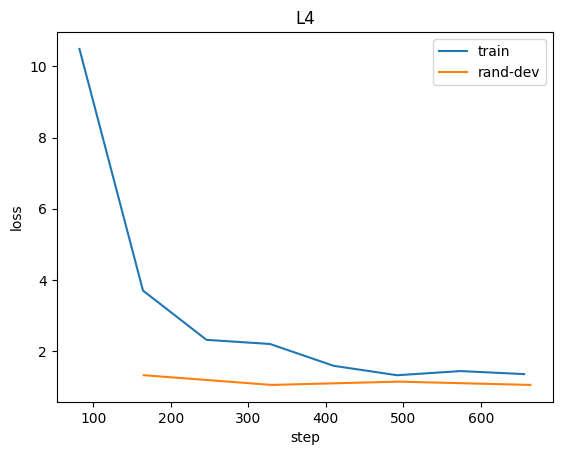

In [19]:
log = pd.DataFrame(trainer.state.log_history)
tr, ev = log.dropna(subset=["loss"]), log.dropna(subset=["eval_loss"])
plt.plot(tr["step"], tr["loss"], label="train")
plt.plot(ev["step"], ev["eval_loss"], label="rand-dev")
plt.xlabel("step"); plt.ylabel("loss"); plt.title(RUN_NAME); plt.legend()
plt.savefig(f"{RUN_DIR}_loss.png", dpi=150)
plt.show()

In [20]:
# Saves the LoRA weights and the trained classification head
model.save_pretrained(f"{RUN_DIR}_adapter")
tokenizer.save_pretrained(f"{RUN_DIR}_adapter")

('/kaggle/working/L4_adapter/tokenizer_config.json',
 '/kaggle/working/L4_adapter/chat_template.jinja',
 '/kaggle/working/L4_adapter/tokenizer.json')

## Evaluation on rand-dev
The predicted class is the argmax over the head's logits, mapped back to its label string,
then scored with the same `evaluate` function as all other runs (invalid outputs are impossible here).

In [21]:
pred = trainer.predict(dev_ds)
logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
raw = [id2label[i] for i in logits.argmax(axis=-1)]

metrics, res = evaluate(dev, raw, labels)
save_results(RUN_NAME + ("_smoke" if SMOKE_TEST else ""), "rand-dev", metrics, res, OUT_DIR,
             {"method": "LoRA", "lang": LANG, "lemma": USE_LEMMA,
              "modules": MODULES_TAG, "output": "cls_head"})

n                 : 570
accuracy          : 0.8579
macro_f1          : 0.6611
invalid_rate      : 0.0000
no_label_rate     : 0.0000
multi_label_rate  : 0.0000
acc_on_valid      : 0.8579
                               precision    recall  f1-score   support

                      animate       0.98      0.97      0.98       218
            dynamic_situation       0.71      0.84      0.77        64
dynamic_situation*information       1.00      0.25      0.40         4
                    inanimate       0.85      0.97      0.90       136
        inanimate*information       0.50      0.50      0.50         2
                  information       0.69      0.65      0.67        51
                  institution       0.29      0.67      0.40         3
                        other       0.71      0.19      0.29        27
                   possession       0.62      0.83      0.71         6
                     quantity       0.84      0.80      0.82        20
            stative_situation   